# Exploració dades

In [13]:
import sys
from pathlib import Path
from google.colab import drive

# --- CONFIGURACIÓ RÀPIDA (LOCAL vs COLAB) ---
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    drive.mount("/content/drive")
    possible_paths = [
        Path("/content/drive/Shareddrives/TFG_Nils_2026"),
        Path("/content/drive/MyDrive/TFG_Nils_2026"),
    ]
    BASE_DIR = next((p for p in possible_paths if p.exists()), possible_paths[0])

    DATA_DIR = BASE_DIR / "02_Data" / "01_Preprocessed_epochs"
    META_DIR = BASE_DIR / "02_Data" / "02_meta"
else:
    BASE_DIR = Path(".").resolve()
    DATA_DIR = BASE_DIR / "data"
    META_DIR = BASE_DIR / "docs"

# Resultat
print(f"Entorn: {'Colab' if IN_COLAB else 'Local'}")
print(f"Base: {BASE_DIR.resolve()}")
print(f"Dades: {DATA_DIR} -> {'✅' if DATA_DIR.exists() else '❌ NO TROBAT (Revisa les rutes)'}")

if DATA_DIR.exists():
    print(f"Mostra fitxers: {[f.name for f in DATA_DIR.glob('*.fif')][:3]}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorn: Colab
Base: /content/drive/.shortcut-targets-by-id/19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU/TFG_Nils_2026
Dades: /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs -> ✅
Mostra fitxers: ['P0002.fif', 'P0003.fif', 'P0004.fif']


Reading /content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P0002.fif ...


/tmp/ipython-input-2682148110.py:4: RuntimeWarning: This filename (/content/drive/MyDrive/TFG_Nils_2026/02_Data/01_Preprocessed_epochs/P0002.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs(DATA_DIR / "P0002.fif", preload=True)


Isotrak not found
    Found the data of interest:
        t =   -1240.00 ...    2000.00 ms
        0 CTF compensation matrices available
Not setting metadata
384 matching events found
No baseline correction applied
0 projection items activated
Using matplotlib as 2D backend.


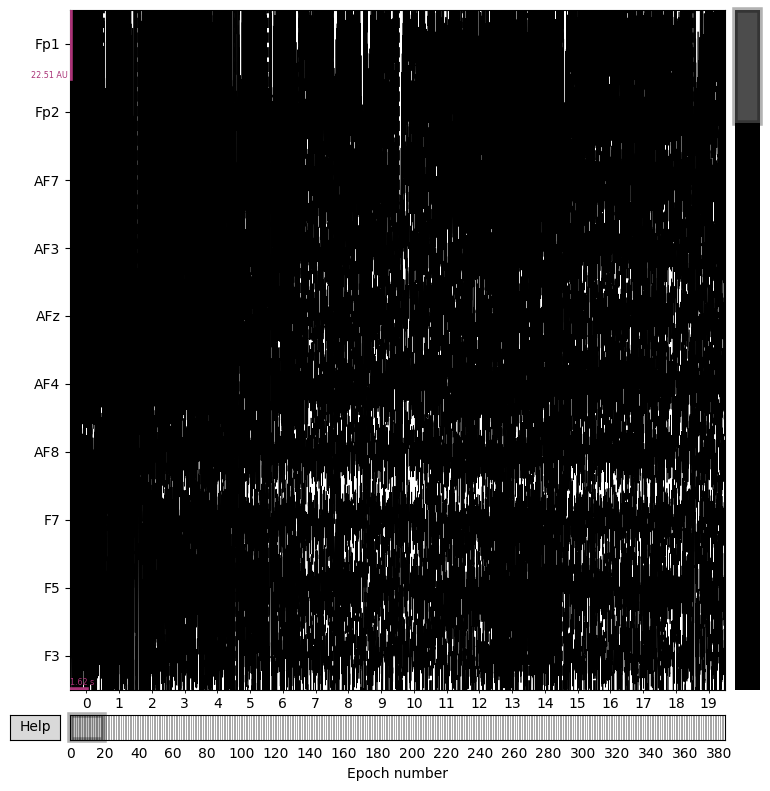

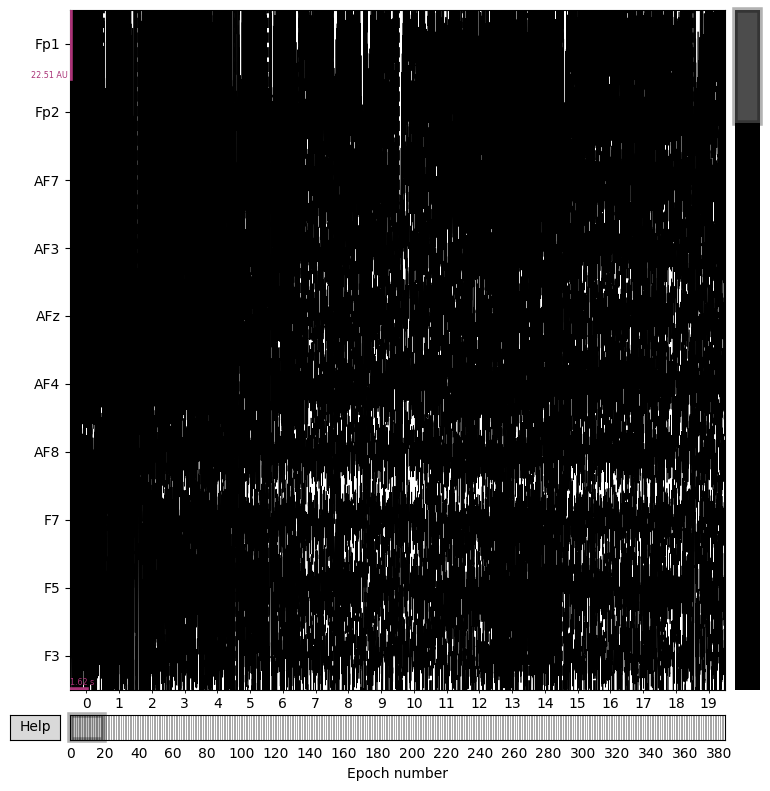

In [ ]:
%pip install -q mne

import mne
import matplotlib.pyplot as plt

# Load and visualize the preprocessed epochs
epochs = mne.read_epochs(DATA_DIR / "P0002.fif", preload=True)
epochs.plot(picks="all", n_channels=10)

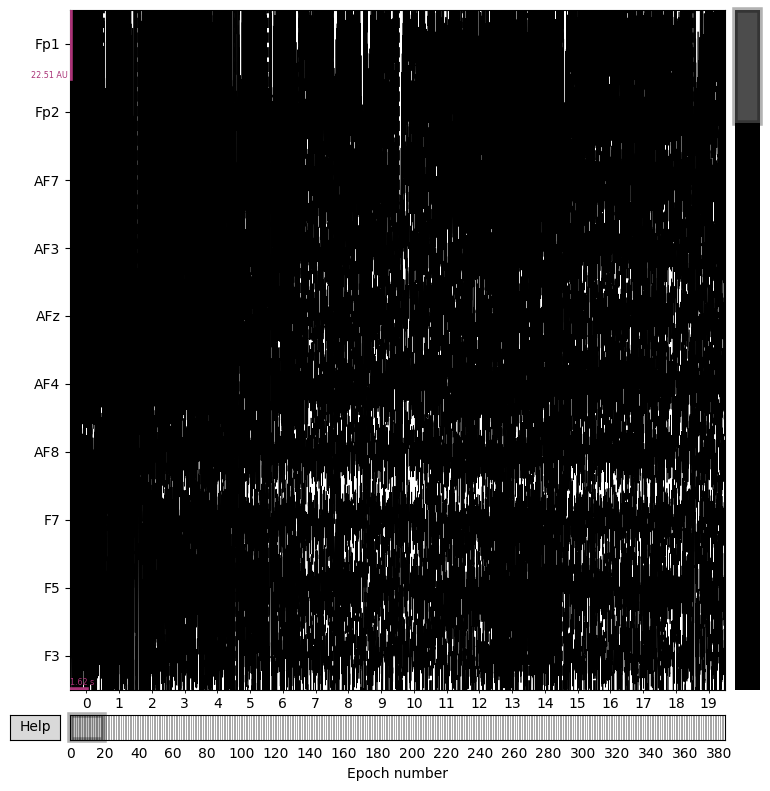

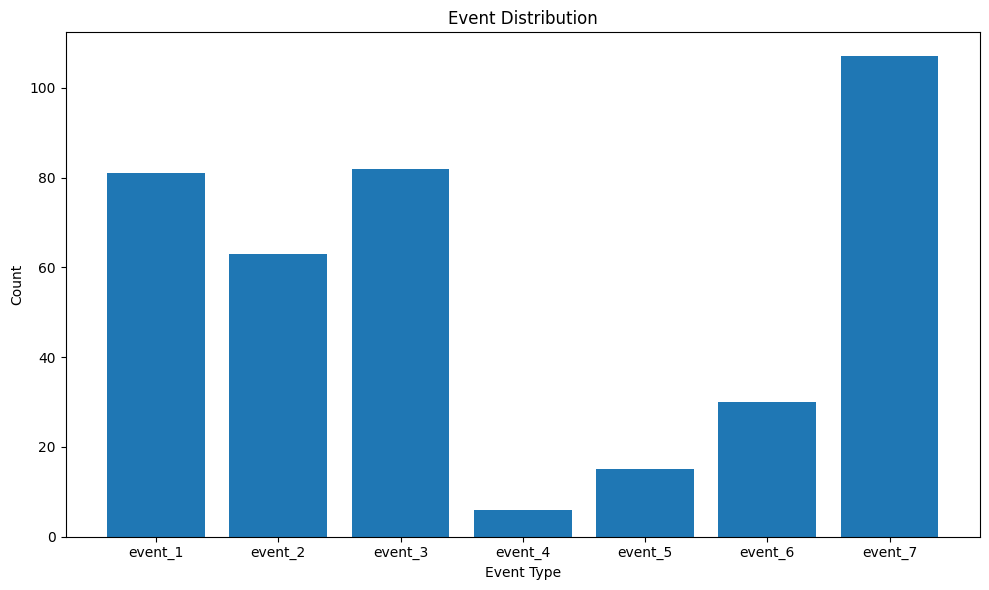

In [17]:
import mne

import matplotlib.pyplot as plt

# Visualize the epochs data
epochs.plot(picks="all", n_channels=10)

# Plot event counts
fig, ax = plt.subplots(figsize=(10, 6))
event_counts = epochs.event_id
ax.bar(event_counts.keys(), [len(epochs[key]) for key in event_counts.keys()])
ax.set_xlabel("Event Type")
ax.set_ylabel("Count")
ax.set_title("Event Distribution")
plt.tight_layout()
plt.show()